<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/susy_field_theory/susyft_visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Supersymmetric Field Theory* — `susyft_visualizations.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Supersymmetric Field Theory — Colab Visualization Notebook
**Based on D. Tong, DAMTP Cambridge · susy.pdf**

This notebook produces **7 self-contained visualizations** spanning Ch 2–7.
Run Setup (Cell 2) first, then any plot cell independently.

| Plot | Chapter | Topic |
|------|---------|-------|
| 1 | Ch 2 §2.3 | Massless multiplets: helicity states and dof counting |
| 2 | Ch 3 §3.2 | Scalar potential V = |F|² for Wess–Zumino and O'Raifeartaigh models |
| 3 | Ch 3 §3.3 | Non-renormalisation: running coupling exact (NSVZ) vs perturbative |
| 4 | Ch 4 §4.3 | SQCD moduli space: D-flat directions and Higgs/Coulomb branches |
| 5 | Ch 5 §5.1 | SQCD phase diagram: β-function and phases vs Nf/Nc |
| 6 | Ch 6 §6.4–5 | Seiberg duality: electric ↔ magnetic, conformal window |
| 7 | Ch 7 §7.3 | Dynamical SUSY breaking: natural hierarchy m_SUSY vs g² |


In [1]:
# ── Setup: run this cell first ───────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import os

BG   = '#1e1e2e'; FG = '#cdd6f4'; EDGE = '#45475a'
GOLD = '#e8b84b'; BLUE = '#7ec8e3'; PURP = '#c792ea'
GREEN= '#90ee90'; RED  = '#e07070'; ORAN = '#e8a838'; TEAL = '#2ec4b6'

plt.rcParams.update({
    'figure.facecolor': BG, 'axes.facecolor': BG,
    'text.color': FG, 'axes.labelcolor': FG,
    'xtick.color': FG, 'ytick.color': FG,
    'axes.edgecolor': EDGE, 'grid.color': EDGE, 'grid.alpha': 0.3,
    'font.size': 12, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlecolor': GOLD, 'legend.framealpha': 0.3,
    'legend.edgecolor': EDGE, 'lines.linewidth': 2.2,
    'axes.linewidth': 1.2, 'figure.dpi': 110,
})

os.makedirs('susyft_figures', exist_ok=True)

def savefig(name):
    plt.savefig(f'susyft_figures/{name}', dpi=150, bbox_inches='tight', facecolor=BG)
    plt.show()
    print(f'Saved: susyft_figures/{name}')

print('Setup complete.')


Setup complete.


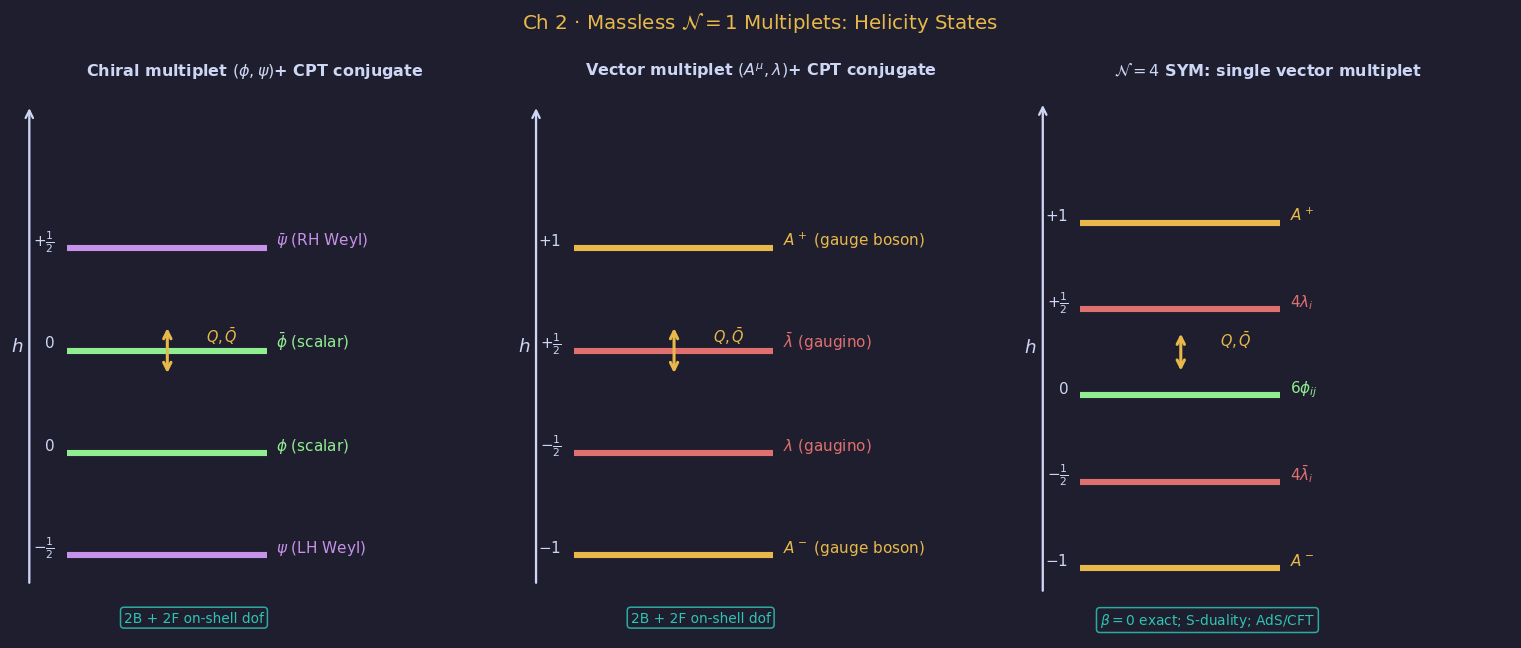

Saved: susyft_figures/plot1_multiplets.png


In [2]:
# ── Plot 1: Massless N=1 multiplets — helicity and dof ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 6))
fig.suptitle(r'Ch 2 · Massless $\mathcal{N}=1$ Multiplets: Helicity States',
             color=GOLD, fontsize=13)

def helicity_diagram(ax, title, states, footer):
    ax.set_facecolor(BG); ax.axis('off')
    ax.set_title(title, color=FG, fontsize=10.5)
    ax.set_xlim(0, 4); ax.set_ylim(-0.8, len(states)+0.6)
    ax.annotate('', xy=(0.14, len(states)+0.4), xytext=(0.14, -0.3),
                arrowprops=dict(arrowstyle='->', color=FG, lw=1.5))
    ax.text(0.04, len(states)/2, r'$h$', ha='center', fontsize=12, color=FG)
    for i, (h_val, label, col) in enumerate(states):
        y = len(states)-1-i
        ax.hlines(y, 0.45, 2.1, colors=col, lw=4)
        ax.text(0.35, y+0.03, h_val, ha='right', fontsize=10, color=FG)
        ax.text(2.18, y+0.03, label, ha='left', fontsize=10, color=col)
    ax.annotate('', xy=(1.28, len(states)/2-0.25), xytext=(1.28, len(states)/2+0.25),
                arrowprops=dict(arrowstyle='<->', color=GOLD, lw=2))
    ax.text(1.6, len(states)/2 +0.15, r'$Q,\bar Q$', fontsize=9.5, color=GOLD, va='center')
    ax.text(1.5, -0.65, footer, ha='center', fontsize=9, color=TEAL,
            bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=TEAL, alpha=0.85))

helicity_diagram(axes[0],
    r'Chiral multiplet $(\phi, \psi)$+ CPT conjugate', [(r'$+\frac{1}{2}$', r'$\bar\psi$ (RH Weyl)', PURP),
     (r'$0$',            r'$\bar\phi$ (scalar)',   GREEN),
     (r'$0$',            r'$\phi$ (scalar)',        GREEN),
     (r'$-\frac{1}{2}$', r'$\psi$ (LH Weyl)',      PURP)],
    '2B + 2F on-shell dof')

helicity_diagram(axes[1],
    r'Vector multiplet $(A^\mu, \lambda)$+ CPT conjugate',
    [(r'$+1$',           r'$A^+$ (gauge boson)',    GOLD),
     (r'$+\frac{1}{2}$', r'$\bar\lambda$ (gaugino)',RED),
     (r'$-\frac{1}{2}$', r'$\lambda$ (gaugino)',    RED),
     (r'$-1$',           r'$A^-$ (gauge boson)',    GOLD)],
    '2B + 2F on-shell dof')

# N=4 multiplet
helicity_diagram(axes[2],
    r'$\mathcal{N}=4$ SYM: single vector multiplet',
    [(r'$+1$',           r'$A^+$',    GOLD),
     (r'$+ \frac{1}{2}$', r'$4\lambda_i$', RED),
     (r'$0$',            r'$6\phi_{ij}$', GREEN),
     (r'$-\frac{1}{2}$', r'$4\bar\lambda_i$', RED),
     (r'$-1$',           r'$A^-$',    GOLD)],
    r'$\beta=0$ exact; S-duality; AdS/CFT')

plt.tight_layout()
savefig('plot1_multiplets.png')


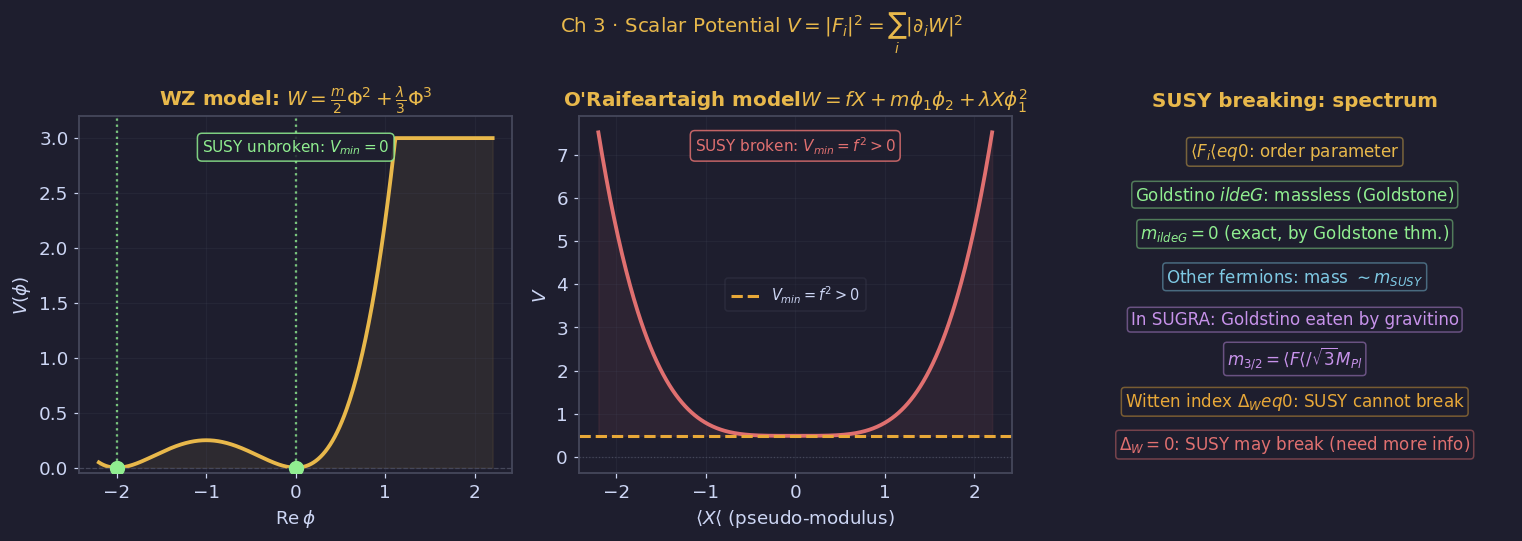

Saved: susyft_figures/plot2_scalar_potential.png


In [3]:
# ── Plot 2: Scalar potential V = |W'|² for WZ and O'Raifeartaigh models ──────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle(r'Ch 3 · Scalar Potential $V=|F_i|^2=\sum_i|\partial_i W|^2$',
             color=GOLD, fontsize=13)

x = np.linspace(-2.2, 2.2, 500)

# WZ model: W = mx²/2 + λx³/3
m, lam = 1.0, 0.5
hp_wz  = m*x + lam*x**2
V_wz   = hp_wz**2

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'WZ model: $W= \frac{m}{2}\Phi^2+\frac{\lambda}{3}\Phi^3$', color=GOLD)
ax.plot(x, np.clip(V_wz, 0, 3), color=GOLD, lw=2.5)
ax.fill_between(x, 0, np.clip(V_wz, 0, 3), color=GOLD, alpha=0.08)
ax.axhline(0, color=EDGE, lw=0.8, ls='--')
zeros = [-m/lam, 0]
for z in zeros:
    ax.axvline(z, color=GREEN, lw=1.5, ls=':', alpha=0.8)
    ax.plot(z, 0, 'o', color=GREEN, ms=9, zorder=6)
ax.text(0.5, 0.9, r'SUSY unbroken: $V_{min}=0$', transform=ax.transAxes,
        ha='center', fontsize=10, color=GREEN,
        bbox=dict(boxstyle='round', fc=BG, ec=GREEN, alpha=0.85))
ax.set_xlabel(r'$\mathrm{Re}\,\phi$'); ax.set_ylabel(r'$V(\phi)$')
ax.set_ylim(-0.05, 3.2); ax.grid(True, alpha=0.2)

# O'Raifeartaigh: V ≥ f² > 0
f = 0.7
x2 = np.linspace(-2.2, 2.2, 500)
# Simplified: V = f² + λ²|x|⁴ (schematic: shows flat pseudo-moduli space)
V_OR = f**2 + 0.3*x2**4

ax = axes[1]; ax.set_facecolor(BG)
ax.set_title("O'Raifeartaigh model" + r"$W=fX+m\phi_1\phi_2+\lambda X\phi_1^2$", color=GOLD)
ax.plot(x2, V_OR, color=RED, lw=2.5)
ax.fill_between(x2, f**2, V_OR, color=RED, alpha=0.08)
ax.axhline(f**2, color=ORAN, lw=2, ls='--', label=r'$V_{min}=f^2>0$')
ax.axhline(0, color=EDGE, lw=0.8, ls=':')
ax.legend(fontsize=9.5); ax.set_xlabel(r'$\langle X\langle$ (pseudo-modulus)')
ax.set_ylabel(r'$V$'); ax.grid(True, alpha=0.2)
ax.text(0.5, 0.9, 'SUSY broken: $V_{min}=f^2>0$', transform=ax.transAxes,
        ha='center', fontsize=10, color=RED,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.85))

# Goldstino mass = 0
ax = axes[2]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('SUSY breaking: spectrum', color=GOLD)
items = [
    (0.5, 0.90, r'$\langle F_i \langle eq 0$: order parameter', GOLD),
    (0.5, 0.78, r'Goldstino $\tilde G$: massless (Goldstone)', GREEN),
    (0.5, 0.67, r'$m_{\tilde G}=0$ (exact, by Goldstone thm.)', GREEN),
    (0.5, 0.55, r'Other fermions: mass $\sim m_{SUSY}$', BLUE),
    (0.5, 0.43, r'In SUGRA: Goldstino eaten by gravitino', PURP),
    (0.5, 0.32, r'$m_{3/2}=\langle F \langle/\sqrt{3}M_{Pl}$', PURP),
    (0.5, 0.20, r'Witten index $\Delta_W eq 0$: SUSY cannot break', ORAN),
    (0.5, 0.08, r'$\Delta_W=0$: SUSY may break (need more info)', RED),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.45))

plt.tight_layout()
savefig('plot2_scalar_potential.png')


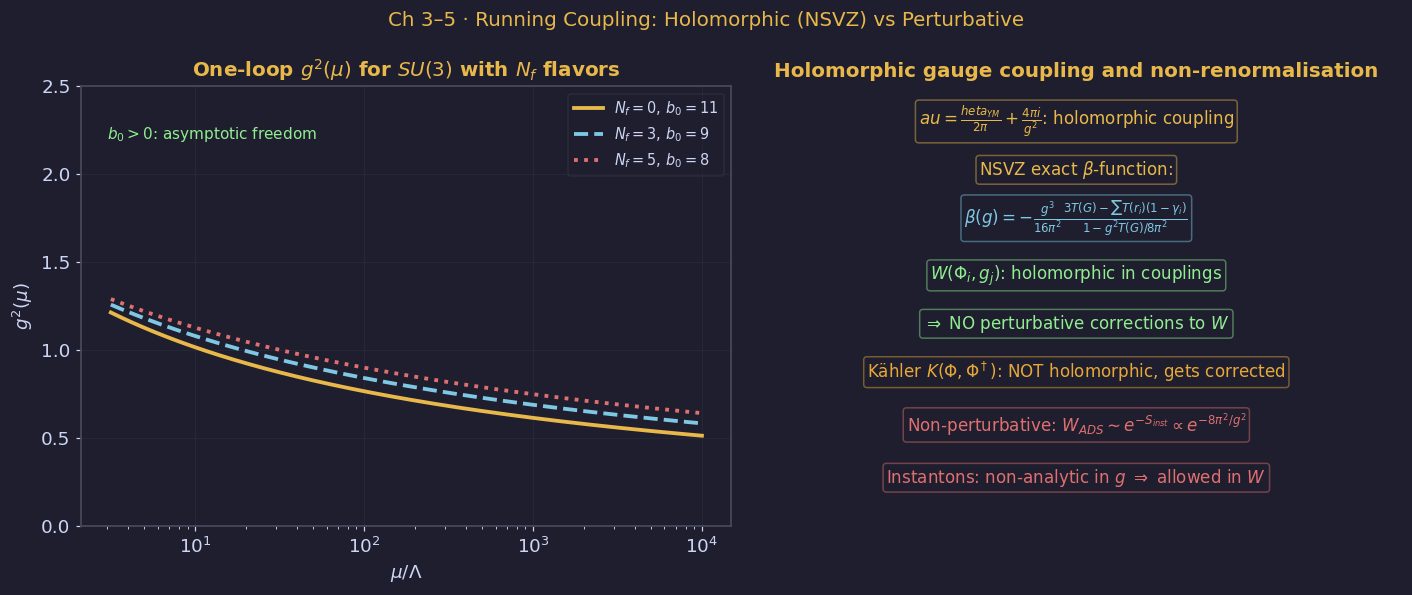

Saved: susyft_figures/plot3_running_coupling.png


In [4]:
# ── Plot 3: Running coupling — NSVZ exact vs perturbative ────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle('Ch 3–5 · Running Coupling: Holomorphic (NSVZ) vs Perturbative',
             color=GOLD, fontsize=13)

mu_over_Lambda = np.logspace(0.5, 4, 400)   # μ/Λ from ~3 to 10000
Nc, Nf_vals = 3, [0, 3, 5]

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'One-loop $g^2(\mu)$ for $SU(3)$ with $N_f$ flavors', color=GOLD)

for Nf, col, ls in zip(Nf_vals, [GOLD, BLUE, RED], ['-','--',':']):
    b0 = (11*Nc/3 - 2*Nf/3)
    alpha_inv0 = 1.0/0.12   # at μ = Λ (fixed reference)
    alpha_inv = alpha_inv0 + b0/(2*np.pi) * np.log(mu_over_Lambda)
    g2 = np.where(alpha_inv > 0.2, 4*np.pi/alpha_inv, np.nan)
    ax.semilogx(mu_over_Lambda, g2, color=col, lw=2.5, ls=ls,
                label=fr'$N_f={Nf}$, $b_0={(11*Nc//3 - 2*Nf//3):.0f}$' +
                      (' (IR free)' if b0 < 0 else ''))

ax.set_xlabel(r'$\mu/\Lambda$'); ax.set_ylabel(r'$g^2(\mu)$')
ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2)
ax.set_ylim(0, 2.5)
ax.text(3, 2.2, r'$b_0>0$: asymptotic freedom', fontsize=10, color=GREEN)

# Right: holomorphic τ and NSVZ
ax = axes[1]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Holomorphic gauge coupling and non-renormalisation', color=GOLD)

items = [
    (0.5, 0.92, r'$\tau = \frac{\theta_{YM}}{2\pi}+\frac{4\pi i}{g^2}$: holomorphic coupling', GOLD),
    (0.5, 0.81, r'NSVZ exact $\beta$-function:', GOLD),
    (0.5, 0.70, r'$\beta(g)=-\frac{g^3}{16\pi^2} \frac{3T(G)-\sum T(r_i)(1-\gamma_i)}{1-g^2T(G)/8\pi^2}$',
     BLUE),
    (0.5, 0.57, r'$W(\Phi_i, g_j)$: holomorphic in couplings', GREEN),
    (0.5, 0.46, r'$\Rightarrow$ NO perturbative corrections to $W$', GREEN),
    (0.5, 0.35, r'Kähler $K(\Phi,\Phi^\dagger)$: NOT holomorphic, gets corrected', ORAN),
    (0.5, 0.23, r'Non-perturbative: $W_{ADS}\sim e^{-S_{inst}}\propto e^{-8\pi^2/g^2}$', RED),
    (0.5, 0.11, r'Instantons: non-analytic in $g$ $\Rightarrow$ allowed in $W$', RED),
]
for x_,y_,txt,col in items:
    ax.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
            transform=ax.transAxes,
            bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.45))

plt.tight_layout()
savefig('plot3_running_coupling.png')


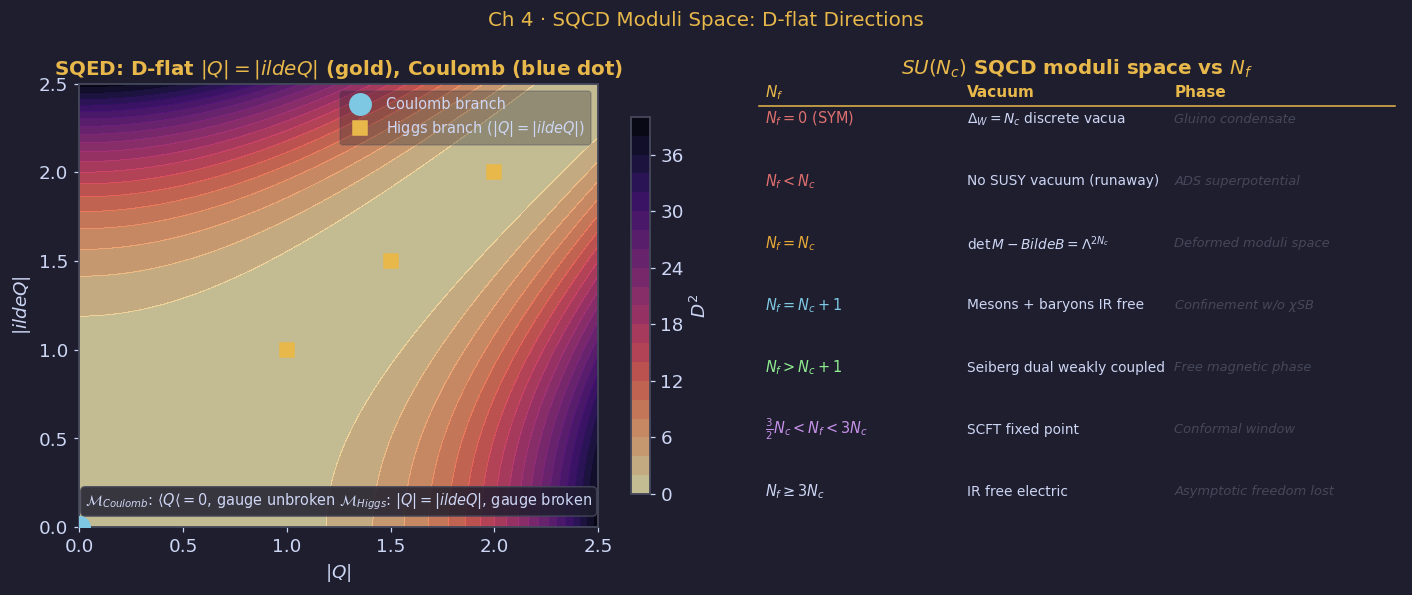

Saved: susyft_figures/plot4_moduli_space.png


In [5]:
# ── Plot 4: SQCD moduli space — D-flat directions, Higgs and Coulomb ─────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Ch 4 · SQCD Moduli Space: D-flat Directions',
             color=GOLD, fontsize=13)

# Left: SQED D-flat directions |Q|² = |Q̃|²
q1 = np.linspace(0, 2.5, 300)
q2 = np.linspace(0, 2.5, 300)
Q1, Q2 = np.meshgrid(q1, q2)
D = (Q1**2 - Q2**2)**2

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'SQED: D-flat $|Q|=|\tilde Q|$ (gold), Coulomb (blue dot)',
             color=GOLD)
cf = ax.contourf(Q1, Q2, D, levels=25, cmap='magma_r', alpha=0.75)
ax.contour(Q1, Q2, D, levels=[0], colors=[GOLD], linewidths=3)
ax.plot(0, 0, 'o', color=BLUE, ms=14, zorder=8, label='Coulomb branch')
ax.plot([1.0, 1.5, 2.0], [1.0, 1.5, 2.0], 's', color=GOLD, ms=9, zorder=8,
        label='Higgs branch ($|Q|=|\tilde Q|$)')
plt.colorbar(cf, ax=ax, label=r'$D^2$', shrink=0.85)
ax.set_xlabel(r'$|Q|$'); ax.set_ylabel(r'$|\tilde Q|$')
ax.legend(fontsize=9.5)
ax.text(0.5, 0.05, r'$\mathcal{M}_{Coulomb}$: $\langle Q \langle=0$, gauge unbroken' +
        ' ' + r'$\mathcal{M}_{Higgs}$: $|Q|=|\tilde Q|$, gauge broken',
        transform=ax.transAxes, ha='center', fontsize=9.5, color=FG,
        bbox=dict(boxstyle='round', fc=BG, ec=EDGE, alpha=0.85))

# Right: SQCD moduli space structure
ax = axes[1]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title(r'$SU(N_c)$ SQCD moduli space vs $N_f$', color=GOLD)

rows = [
    (r'$N_f=0$ (SYM)', r'$\Delta_W=N_c$ discrete vacua', r'Gluino condensate', RED),
    (r'$N_f<N_c$', r'No SUSY vacuum (runaway)', r'ADS superpotential', RED),
    (r'$N_f=N_c$', r'$\det M-B\tilde B=\Lambda^{2N_c}$', r'Deformed moduli space', ORAN),
    (r'$N_f=N_c+1$', r'Mesons + baryons IR free', r'Confinement w/o $\chi$SB', BLUE),
    (r'$N_f>N_c+1$', r'Seiberg dual weakly coupled', r'Free magnetic phase', GREEN),
    (r'$\frac{3}{2}N_c<N_f<3N_c$', r'SCFT fixed point', r'Conformal window', PURP),
    (r'$N_f\geq 3N_c$', r'IR free electric', r'Asymptotic freedom lost', FG),
]
col_xs = [0.02, 0.33, 0.65]
ys = np.linspace(0.92, 0.08, len(rows))
for (nf, vac, desc, col), y in zip(rows, ys):
    ax.text(col_xs[0], y, nf,   color=col,  fontsize=9.5, va='center', transform=ax.transAxes)
    ax.text(col_xs[1], y, vac,  color=FG,   fontsize=9,   va='center', transform=ax.transAxes)
    ax.text(col_xs[2], y, desc, color=EDGE, fontsize=8.5, va='center', transform=ax.transAxes, style='italic')

# Header
for x_, h_, col in zip(col_xs, [r'$N_f$', 'Vacuum', 'Phase'], [GOLD, GOLD, GOLD]):
    ax.text(x_, 0.98, h_, color=col, fontsize=10, fontweight='bold',
            va='center', transform=ax.transAxes)
ax.axhline(0.95, xmin=0.01, xmax=0.99, color=GOLD, lw=1) #, transform=ax.transAxes)

plt.tight_layout()
savefig('plot4_moduli_space.png')


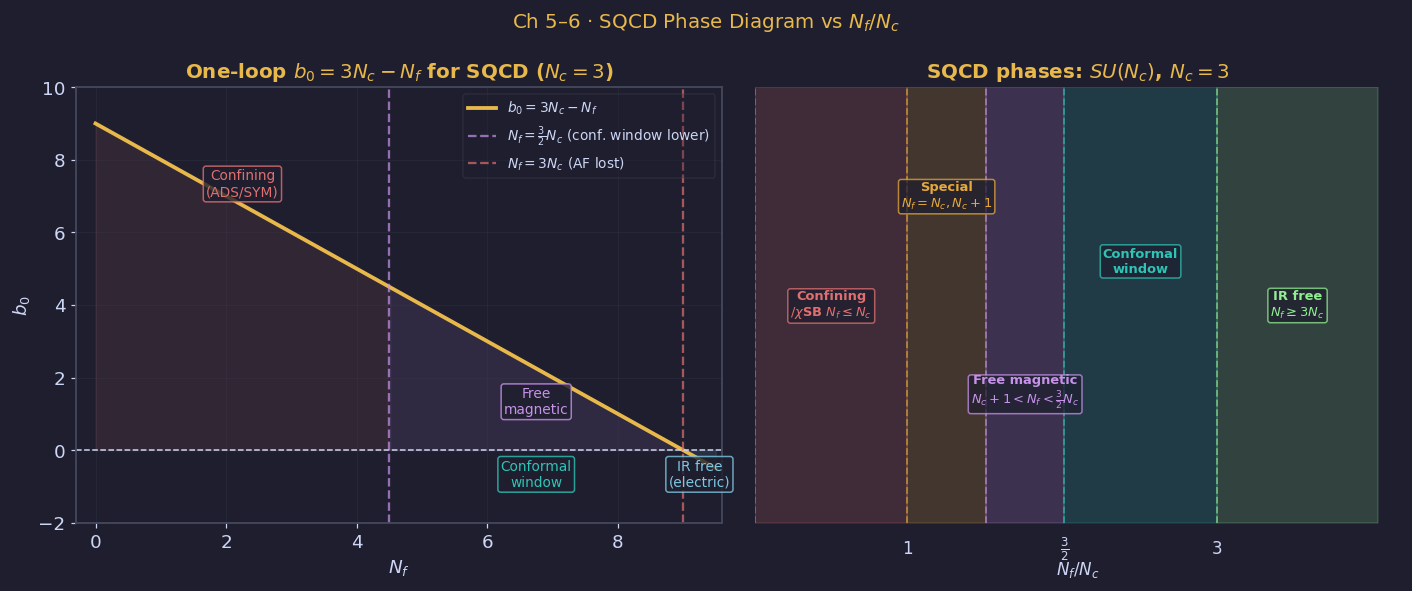

Saved: susyft_figures/plot5_phase_diagram.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
fig.suptitle(r'Ch 5–6 · SQCD Phase Diagram vs $N_f/N_c$',
             color=GOLD, fontsize=13)

Nc = 3
Nf_cont = np.linspace(0, 3*Nc+0.5, 300)
b0_susy = 3*Nc - Nf_cont

ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'One-loop $b_0=3N_c-N_f$ for SQCD ($N_c=3$)', color=GOLD)
ax.plot(Nf_cont, b0_susy, color=GOLD, lw=2.5, label=r'$b_0=3N_c-N_f$')
ax.axhline(0, color=FG, lw=1, ls='--')
ax.axvline(3*Nc/2, color=PURP, lw=1.5, ls='--', alpha=0.7,
           label=r'$N_f=\frac{3}{2}N_c$ (conf. window lower)')
ax.axvline(3*Nc,   color=RED,  lw=1.5, ls='--', alpha=0.7,
           label=r'$N_f=3N_c$ (AF lost)')

ax.fill_between(Nf_cont, 0, b0_susy,
                where=(Nf_cont < 3*Nc/2), color=RED,  alpha=0.10)
ax.fill_between(Nf_cont, 0, b0_susy,
                where=(Nf_cont >= 3*Nc/2) & (Nf_cont < 3*Nc), color=PURP, alpha=0.10)
ax.fill_between(Nf_cont, 0, b0_susy,
                where=(Nf_cont >= 3*Nc),  color=BLUE, alpha=0.10)

ax.set_xlabel(r'$N_f$'); ax.set_ylabel(r'$b_0$')
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

ax.set_ylim(-2.0, 10)
ax.set_xlim(-0.3, 3*Nc + 0.6)

for x_, y_, txt, col in [
    (2.25, 7.0,  'Confining\n(ADS/SYM)',   RED),    # Nf<4.5 구간, b0 높은 곳
    (6.75, 1.0,  'Free\nmagnetic',          PURP),   # Nf=4.5~9, b0 양수 구간
    (6.75, -1.0, 'Conformal\nwindow',       TEAL),   # Nf=4.5~9, b0 음수 구간 바로 위
    (9.25, -1.0, 'IR free\n(electric)',     BLUE),   # Nf>9 구간
]:
    ax.text(x_, y_, txt, ha='center', fontsize=9, color=col,
            bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.8))

# Right: phase diagram strip
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'SQCD phases: $SU(N_c)$, $N_c=3$', color=GOLD)
ax2.set_xlim(0, 1.4); ax2.set_ylim(0, 1); ax2.axis('off')

regions = [
    (0.00, 0.33, 'Confining\n' + r'$/\chi$SB $N_f\leq N_c$',          RED,   0.165, 0.50),
    (0.33, 0.50, 'Special\n'   + r'$N_f=N_c,N_c+1$',                  ORAN,  0.415, 0.75),
    (0.50, 0.67, 'Free magnetic\n' + r'$N_c+1<N_f<\frac{3}{2}N_c$',   PURP,  0.585, 0.30),
    (0.67, 1.00, 'Conformal\nwindow',                                   TEAL,  0.835, 0.60),
    (1.00, 1.35, 'IR free\n'   + r'$N_f\geq 3N_c$',                    GREEN, 1.175, 0.50),
]
ax2.set_xlim(0, 1.4)
for x0, x1, lbl, col, xm, yl in regions:
    ax2.fill_between([x0,x1],[0,0],[1,1], alpha=0.18, color=col)
    ax2.axvline(x0, color=col, lw=1.2, ls='--', alpha=0.6)
    ax2.text(xm, yl, lbl, ha='center', va='center',
             fontsize=8.5, color=col, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', fc=BG, ec=col, alpha=0.75))

for xv, lbl in [(0.33,'1'),(0.67,r'$\frac{3}{2}$'),(1.00,'3')]:
    ax2.text(xv, -0.07, lbl, ha='center', fontsize=11, color=FG)
ax2.text(0.7, -0.12, r'$N_f/N_c$', ha='center', fontsize=11, color=FG)

plt.tight_layout()
savefig('plot5_phase_diagram.png')

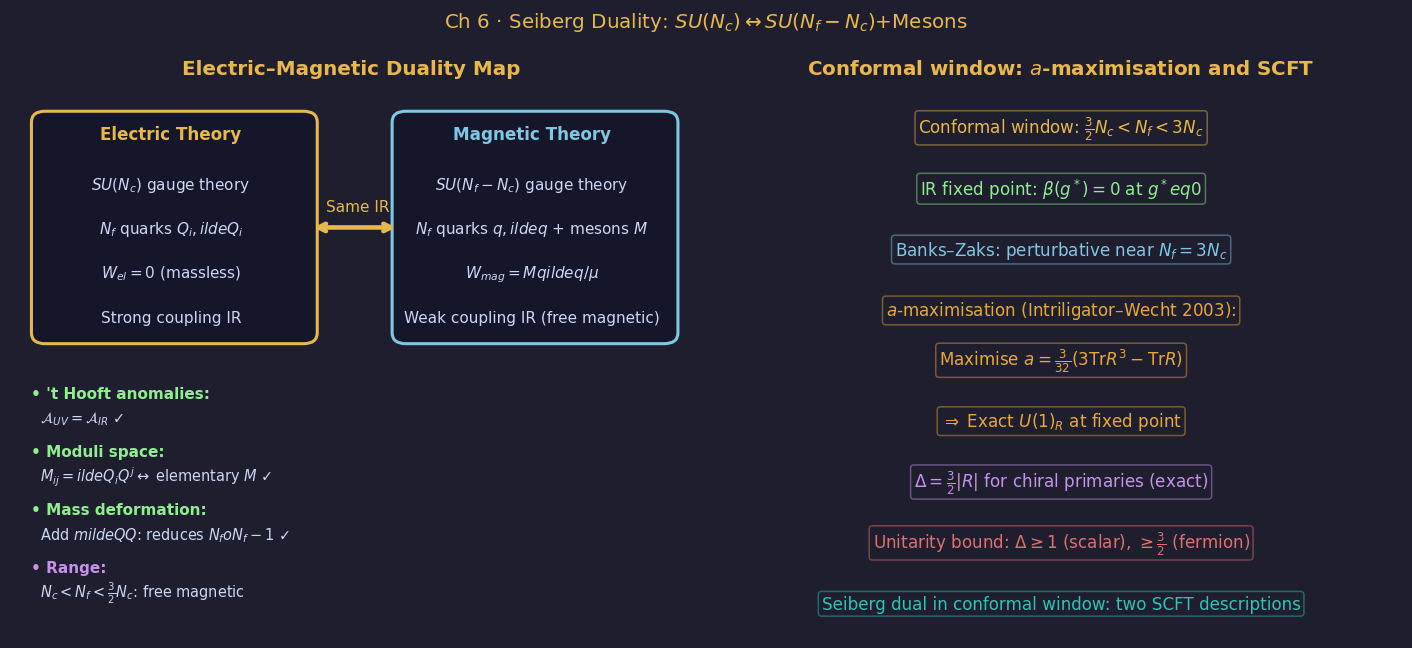

Saved: susyft_figures/plot6_seiberg_duality.png


In [7]:
# ── Plot 6: Seiberg duality — electric vs magnetic, anomaly matching ──────────
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.suptitle(r'Ch 6 · Seiberg Duality: $SU(N_c)\leftrightarrow SU(N_f-N_c)$+Mesons',
             color=GOLD, fontsize=13)

# Left: duality map diagram
ax = axes[0]; ax.set_facecolor(BG); ax.axis('off')
ax.set_title('Electric–Magnetic Duality Map', color=GOLD)

# Electric box
erect = FancyBboxPatch((0.05, 0.55), 0.38, 0.38,
                       boxstyle='round,pad=0.02', fc='#16162a', ec=GOLD, lw=2,
                       transform=ax.transAxes)
ax.add_patch(erect)
ax.text(0.235, 0.90, 'Electric Theory', ha='center', fontsize=11,
        color=GOLD, fontweight='bold', transform=ax.transAxes)
for y_, txt in [(0.81, r'$SU(N_c)$ gauge theory'),
                (0.73, r'$N_f$ quarks $Q_i, \tilde Q_i$'),
                (0.65, r'$W_{el}=0$ (massless)'),
                (0.57, r'Strong coupling IR')]:
    ax.text(0.235, y_, txt, ha='center', fontsize=10, color=FG, transform=ax.transAxes)

# Magnetic box
mrect = FancyBboxPatch((0.58, 0.55), 0.38, 0.38,
                       boxstyle='round,pad=0.02', fc='#16162a', ec=BLUE, lw=2,
                       transform=ax.transAxes)
ax.add_patch(mrect)
ax.text(0.765, 0.90, 'Magnetic Theory', ha='center', fontsize=11,
        color=BLUE, fontweight='bold', transform=ax.transAxes)
for y_, txt in [(0.81, r'$SU(N_f-N_c)$ gauge theory'),
                (0.73, r'$N_f$ quarks $q, \tilde q$ + mesons $M$'),
                (0.65, r'$W_{mag}=Mq\tilde q/\mu$'),
                (0.57, r'Weak coupling IR (free magnetic)')]:
    ax.text(0.765, y_, txt, ha='center', fontsize=10, color=FG, transform=ax.transAxes)

# Arrow
ax.annotate('', xy=(0.57, 0.74), xytext=(0.44, 0.74),
            xycoords='axes fraction', textcoords='axes fraction',
            arrowprops=dict(arrowstyle='<->', color=GOLD, lw=3))
ax.text(0.51, 0.77, 'Same IR', ha='center', fontsize=10, color=GOLD,
        transform=ax.transAxes)

# Checks
checks = [
    (r"'t Hooft anomalies", r'$\mathcal{A}_{UV}=\mathcal{A}_{IR}$ ✓', GREEN),
    (r'Moduli space', r'$M_{ij}=\tilde Q_i Q^j \leftrightarrow$ elementary $M$ ✓', GREEN),
    (r'Mass deformation', r'Add $m\tilde QQ$: reduces $N_f\to N_f-1$ ✓', GREEN),
    (r'Range', r'$N_c<N_f<\frac{3}{2}N_c$: free magnetic', PURP),
]
for i, (label, val, col) in enumerate(checks):
    y = 0.44 - i*0.105
    ax.text(0.03, y, f'• {label}:', fontsize=10, color=col,
            fontweight='bold', transform=ax.transAxes, va='center')
    ax.text(0.03, y-0.045, f'  {val}', fontsize=9.5, color=FG,
            transform=ax.transAxes, va='center')

# Right: conformal window and a-function
ax2 = axes[1]; ax2.set_facecolor(BG)
ax2.set_title(r'Conformal window: $a$-maximisation and SCFT', color=GOLD)
ax2.axis('off')

items = [
    (0.5, 0.92, r'Conformal window: $\frac{3}{2}N_c<N_f<3N_c$', GOLD),
    (0.5, 0.81, r'IR fixed point: $\beta(g^*)=0$ at $g^* eq 0$', GREEN),
    (0.5, 0.70, r'Banks–Zaks: perturbative near $N_f=3N_c$', BLUE),
    (0.5, 0.59, r'$a$-maximisation (Intriligator–Wecht 2003):', ORAN),
    (0.5, 0.50, r'Maximise $a=\frac{3}{32}(3\mathrm{Tr}R^3-\mathrm{Tr}R)$', ORAN),
    (0.5, 0.39, r'$\Rightarrow$ Exact $U(1)_R$ at fixed point', ORAN),
    (0.5, 0.28, r'$\Delta=\frac{3}{2}|R|$ for chiral primaries (exact)', PURP),
    (0.5, 0.17, r'Unitarity bound: $\Delta\geq 1$ (scalar), $\geq \frac{3}{2}$ (fermion)', RED),
    (0.5, 0.06, r'Seiberg dual in conformal window: two SCFT descriptions', TEAL),
]
for x_,y_,txt,col in items:
    ax2.text(x_,y_,txt,ha='center',va='center',fontsize=11,color=col,
             transform=ax2.transAxes,
             bbox=dict(boxstyle='round,pad=0.2',fc=BG,ec=col,alpha=0.45))

plt.tight_layout()
savefig('plot6_seiberg_duality.png')


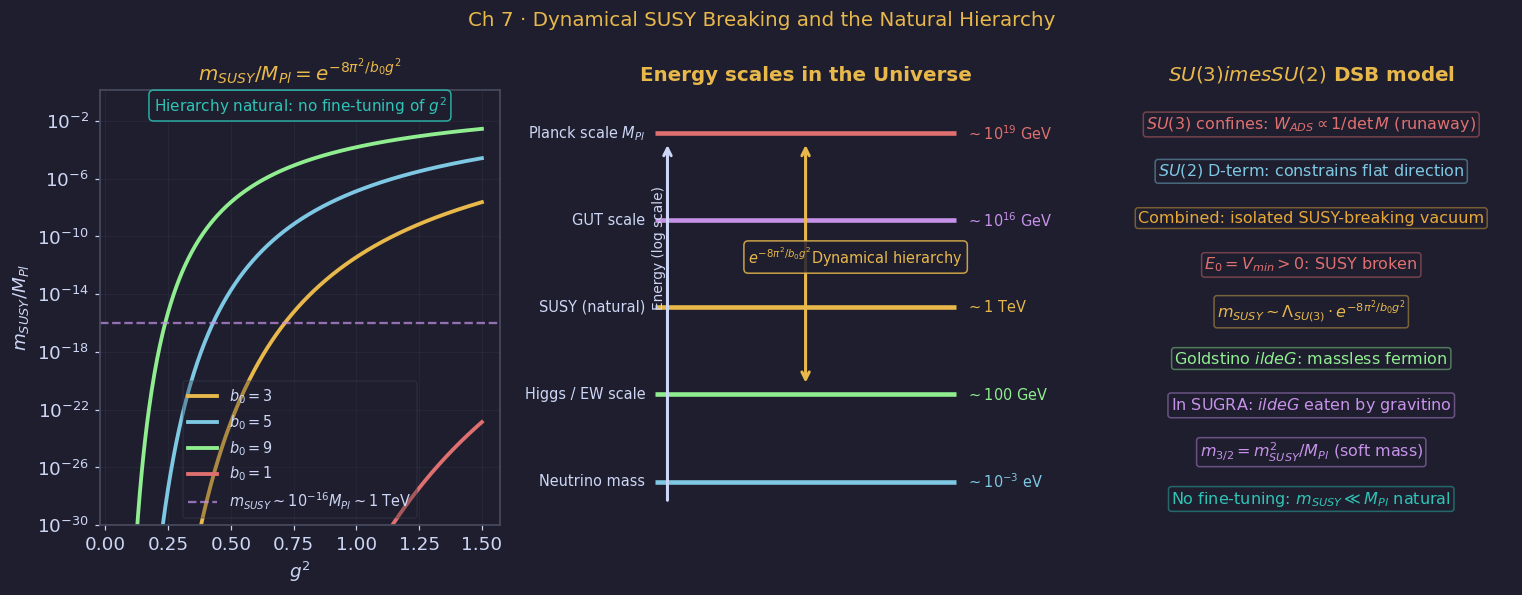

Saved: susyft_figures/plot7_dsb_hierarchy.png


In [8]:
# ── Plot 7: Dynamical SUSY breaking — natural hierarchy ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
fig.suptitle('Ch 7 · Dynamical SUSY Breaking and the Natural Hierarchy',
             color=GOLD, fontsize=13)

# Panel 1: m_SUSY/M_Pl vs g² for different b₀
ax = axes[0]; ax.set_facecolor(BG)
ax.set_title(r'$m_{SUSY}/M_{Pl} = e^{-8\pi^2/b_0 g^2}$', color=GOLD)
g2 = np.linspace(0.05, 1.5, 400)
for b0, col, lbl in [(3, GOLD, '$b_0=3$'), (5, BLUE, '$b_0=5$'),
                     (9, GREEN, '$b_0=9$'), (1, RED, '$b_0=1$')]:
    exponent = -8*np.pi**2 / (b0 * g2)
    ratio = np.exp(exponent)
    ax.semilogy(g2, ratio, color=col, lw=2.5, label=lbl)
ax.axhline(1e-16, color=PURP, lw=1.5, ls='--', alpha=0.7,
           label=r'$m_{SUSY}\sim 10^{-16}M_{Pl}\sim 1$ TeV')
ax.set_xlabel(r'$g^2$'); ax.set_ylabel(r'$m_{SUSY}/M_{Pl}$')
ax.set_ylim(1e-30, 1.5); ax.legend(fontsize=9.5); ax.grid(True, alpha=0.2)
ax.text(0.5, 0.95, 'Hierarchy natural: no fine-tuning of $g^2$',
        transform=ax.transAxes, ha='center', fontsize=10, color=TEAL,
        bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.85))

# Panel 2: hierarchy energy scales
ax2 = axes[1]; ax2.set_facecolor(BG); ax2.axis('off')
ax2.set_title('Energy scales in the Universe', color=GOLD)
ax2.set_xlim(0, 4); ax2.set_ylim(0, 10)

scales = [
    (1, r'$\sim 10^{-3}$ eV', 'Neutrino mass', BLUE),
    (3, r'$\sim 100$ GeV', 'Higgs / EW scale', GREEN),
    (5, r'$\sim 1$ TeV', 'SUSY (natural)', GOLD),
    (7, r'$\sim 10^{16}$ GeV', 'GUT scale', PURP),
    (9, r'$\sim 10^{19}$ GeV', 'Planck scale $M_{Pl}$', RED),
]
for y_, val, desc, col in scales:
    ax2.hlines(y_, 0.5, 3.5, colors=col, lw=3)
    ax2.text(3.6, y_, val, ha='left', fontsize=9.5, color=col, va='center')
    ax2.text(0.4, y_, desc, ha='right', fontsize=9.5, color=FG, va='center')

ax2.annotate('', xy=(0.62, 8.8), xytext=(0.62, 0.5),
             arrowprops=dict(arrowstyle='->', color=FG, lw=2))
ax2.text(0.54, 5, 'Energy (log scale)', ha='center', fontsize=9, color=FG, rotation=90)

ax2.annotate('', xy=(2.0, 3.2), xytext=(2.0, 8.8),
             arrowprops=dict(arrowstyle='<->', color=GOLD, lw=2))
ax2.text(2.5, 6.0, r'$e^{-8\pi^2/b_0 g^2}$' + 'Dynamical hierarchy',
         ha='center', fontsize=9.5, color=GOLD,
         bbox=dict(boxstyle='round', fc=BG, ec=GOLD, alpha=0.85))

# Panel 3: SU(3)×SU(2) mechanism
ax3 = axes[2]; ax3.set_facecolor(BG); ax3.axis('off')
ax3.set_title(r'$SU(3)\times SU(2)$ DSB model', color=GOLD)

steps = [
    r'$SU(3)$ confines: $W_{ADS}\propto 1/\det M$ (runaway)',
    r'$SU(2)$ D-term: constrains flat direction',
    r'Combined: isolated SUSY-breaking vacuum',
    r'$E_0 = V_{min} > 0$: SUSY broken',
    r'$m_{SUSY} \sim \Lambda_{SU(3)} \cdot e^{-8\pi^2/b_0 g^2}$',
    r'Goldstino $\tilde G$: massless fermion',
    r'In SUGRA: $\tilde G$ eaten by gravitino',
    r'$m_{3/2} = m_{SUSY}^2/M_{Pl}$ (soft mass)',
    r'No fine-tuning: $m_{SUSY}\ll M_{Pl}$ natural',
]
colors_steps = [RED, BLUE, ORAN, RED, GOLD, GREEN, PURP, PURP, TEAL]
ys = np.linspace(0.92, 0.06, len(steps))
for txt, y, col in zip(steps, ys, colors_steps):
    ax3.text(0.5, y, txt, ha='center', va='center', fontsize=10.5, color=col,
             transform=ax3.transAxes,
             bbox=dict(boxstyle='round,pad=0.18', fc=BG, ec=col, alpha=0.45))

plt.tight_layout()
savefig('plot7_dsb_hierarchy.png')


In [9]:
# ── Download all figures ─────────────────────────────────────────────────────
import shutil
shutil.make_archive('susyft_figures', 'zip', 'susyft_figures')
try:
    from google.colab import files
    files.download('susyft_figures.zip')
    print('Download triggered.')
except ImportError:
    print('Not in Colab — figures saved to susyft_figures/')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered.
